# 02 – Tiền xử lý dữ liệu
Đầu ra chính:
1. `outputs/basket_items.csv.gz` – bảng giỏ hàng sạch (mỗi dòng = 1 nhóm hàng trong 1 giỏ, đủ 3 cấp department / commodity / sub-commodity), dùng cho notebook 04.
2. `outputs/household_base.csv` – Bộ dữ liệu 1 cấp hộ (1.584 hộ nhận chiến dịch, nhãn `redeemed`), dùng cho notebook 05.
3. `outputs/split.csv` – chia train/test dùng chung cho notebook 04 và 05.

In [1]:
# Chạy trên Google Colab: kết nối Drive và chuyển vào thư mục notebooks của dự án (máy cá nhân thì bỏ qua)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/DM_Nhom3_Final/notebooks')  # sửa nếu để thư mục dự án ở chỗ khác
except ImportError:
    pass
print(os.getcwd())

/home/claude/github_repo/Group03-Advanced-Data-Mining-26D1ADV60900402/notebooks


In [2]:
import sys, warnings
sys.path.append('../src'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from style import setup, save, vn, BLUE, ORANGE, GRAY, INK, INK2
setup(); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
DATA='../data/'; SEED=42
trans = pd.read_csv(DATA+'transaction_data.csv.gz'); prod = pd.read_csv(DATA+'product.csv')
demo = pd.read_csv(DATA+'hh_demographic.csv'); ctab = pd.read_csv(DATA+'campaign_table.csv')
coup = pd.read_csv(DATA+'coupon.csv'); red = pd.read_csv(DATA+'coupon_redempt.csv')
log = []   # nhật ký trước/sau
def note(step, df, extra=''):
    log.append({'Bước': step, 'Số dòng': len(df), 'Số giỏ': df.BASKET_ID.nunique() if 'BASKET_ID' in df else None,
                'Số hộ': df.household_key.nunique() if 'household_key' in df else None, 'Ghi chú': extra})
note('0. Dữ liệu gốc (transaction_data)', trans)

## 1. Xử lý dữ liệu không đạt chuẩn

In [3]:
# 1a. Dòng doanh số <= 0 hoặc số lượng = 0 (hàng trả lại, dòng điều chỉnh giá)
bad = (trans.SALES_VALUE<=0) | (trans.QUANTITY<=0)
t = trans[~bad].copy(); note('1a. Bỏ SALES_VALUE ≤ 0 hoặc QUANTITY = 0', t, f'loại {vn(bad.sum())} dòng')
# 1b. RETAIL_DISC dương là sai dấu (giảm giá luôn ≤ 0) -> đưa về 0; đổi dấu các cột giảm giá thành số dương
print('RETAIL_DISC > 0:', (t.RETAIL_DISC>0).sum())
t.loc[t.RETAIL_DISC>0,'RETAIL_DISC'] = 0
for c in ['RETAIL_DISC','COUPON_DISC','COUPON_MATCH_DISC']: t[c] = -t[c]
# 1c. Ghép phân cấp sản phẩm, chuẩn hóa chuỗi
p = prod.copy()
for c in ['DEPARTMENT','COMMODITY_DESC','SUB_COMMODITY_DESC']: p[c] = p[c].astype(str).str.strip()
t = t.merge(p[['PRODUCT_ID','DEPARTMENT','COMMODITY_DESC','SUB_COMMODITY_DESC','BRAND']], on='PRODUCT_ID', how='left')
print('Không ghép được sản phẩm:', t.DEPARTMENT.isna().sum())

RETAIL_DISC > 0: 6


Không ghép được sản phẩm: 0


In [4]:
# 1d. Loại department / commodity không phải hàng hóa thật (xăng, phí, coupon, bưu điện, đóng góp từ thiện...)
NON_MERCH_DEPT = ['KIOSK-GAS','MISC SALES TRAN','MISC. TRANS.','COUP/STR & MFG','CHARITABLE CONT',
                  'POSTAL CENTER','CNTRL/STORE SUP','GM MERCH EXP','', 'nan']
NON_MERCH_COMM = ['COUPON/MISC ITEMS','NO COMMODITY DESCRIPTION','COUPONS/STORE & MFG','COUPON',
                  '(CORP USE ONLY)','MISCELLANEOUS(CORP USE ONLY)','FUEL','UNKNOWN']
drop_d = t.DEPARTMENT.isin(NON_MERCH_DEPT); drop_c = t.COMMODITY_DESC.isin(NON_MERCH_COMM)
print('Doanh số bị loại theo department:', t.loc[drop_d].groupby('DEPARTMENT').SALES_VALUE.sum().round(0).sort_values(ascending=False).to_dict())
clean = t[~(drop_d|drop_c)].copy()
note('1d. Bỏ department/commodity không phải hàng hóa', clean, f'loại {vn((drop_d|drop_c).sum())} dòng')
print('QUANTITY lớn nhất còn lại:', clean.QUANTITY.max(), '| dòng QUANTITY > 100:', (clean.QUANTITY>100).sum())

Doanh số bị loại theo department: {'KIOSK-GAS': 544222.0, 'MISC SALES TRAN': 119960.0, 'MISC. TRANS.': 10679.0, 'COUP/STR & MFG': 1028.0, 'GM MERCH EXP': 101.0, 'CNTRL/STORE SUP': 49.0, 'POSTAL CENTER': 24.0, 'CHARITABLE CONT': 8.0}


QUANTITY lớn nhất còn lại: 144 | dòng QUANTITY > 100: 1


In [5]:
# 1e. Ngoại lai giá trị giỏ (IQR): KHÔNG loại vì là giỏ mua sắm lớn có thật; chỉ đánh dấu và dùng log khi mô hình hóa
bv = clean.groupby('BASKET_ID').SALES_VALUE.sum(); q1,q3 = bv.quantile([.25,.75]); hi = q3+1.5*(q3-q1)
print(f'Giỏ vượt ngưỡng IQR ({hi:.1f}$): {(bv>hi).sum()} giỏ = {(bv>hi).mean():.1%}; giỏ lớn nhất {bv.max():.0f}$')
# 1f. coupon: bỏ dòng trùng
coup_c = coup.drop_duplicates(); print('coupon:', len(coup), '->', len(coup_c))

Giỏ vượt ngưỡng IQR (83.5$): 20389 giỏ = 8.1%; giỏ lớn nhất 682$
coupon: 124548 -> 119384


## 2. Bảng giỏ hàng cho luật kết hợp (Bước 3)

In [6]:
items = clean[['BASKET_ID','household_key','DAY','WEEK_NO','DEPARTMENT','COMMODITY_DESC','SUB_COMMODITY_DESC']]\
          .drop_duplicates(['BASKET_ID','SUB_COMMODITY_DESC'])
note('2. Bảng giỏ hàng (bỏ trùng sub-commodity trong giỏ)', items)
items.to_csv('../outputs/basket_items.csv.gz', index=False, compression='gzip')
nb = items.BASKET_ID.nunique()
lv = pd.DataFrame({lvl: [items[lvl].nunique(), (items.drop_duplicates(['BASKET_ID',lvl]).groupby(lvl).size()/nb >= th).sum(), th]
      for lvl,th in [('DEPARTMENT',0.10),('COMMODITY_DESC',0.02),('SUB_COMMODITY_DESC',0.005)]},
      index=['Số item','Số item đạt ngưỡng support','Ngưỡng support dự kiến']).T
print('Số giỏ:', nb); lv

Số giỏ: 250942


,Số item,Số item đạt ngưỡng support,Ngưỡng support dự kiến
DEPARTMENT,28.0,7.0,0.100
COMMODITY_DESC,299.0,111.0,0.020
SUB_COMMODITY_DESC,2355.0,427.0,0.005


## 3. Bộ dữ liệu 1 – bảng cấp hộ cho phân lớp (Bước 4)

In [7]:
g = clean.groupby('household_key')
base = pd.DataFrame({
  'recency':      711 - g.DAY.max(),                       # số ngày từ lần mua cuối đến cuối kỳ
  'frequency':    g.BASKET_ID.nunique(),                   # số giỏ
  'monetary':     g.SALES_VALUE.sum(),                     # tổng chi tiêu
  'tenure_weeks': (g.DAY.max()-g.DAY.min())/7 + 1,         # số tuần hoạt động
  'n_dept':       g.DEPARTMENT.nunique(),
  'n_commodity':  g.COMMODITY_DESC.nunique(),
  'n_stores':     g.STORE_ID.nunique(),
  'private_share':g.apply(lambda d: (d.BRAND=='Private').mean()),
  'retail_disc_share': g.RETAIL_DISC.sum()/g.SALES_VALUE.sum(),
  'items_per_basket': g.size()/g.BASKET_ID.nunique(),
})
base['avg_basket_value'] = base.monetary/base.frequency
base['weekly_spend'] = base.monetary/base.tenure_weeks
base['baskets_per_week'] = base.frequency/base.tenure_weeks
# Chiến dịch được nhận (phơi nhiễm) – KHÔNG chứa thông tin dùng coupon
camp = ctab.groupby('household_key').CAMPAIGN.nunique().rename('n_camp').to_frame()
for ty in ['TypeA','TypeB','TypeC']: camp['n_'+ty] = ctab[ctab.DESCRIPTION==ty].groupby('household_key').CAMPAIGN.nunique()
camp = camp.fillna(0).astype(int)
# Nhân khẩu học -> biến thứ bậc; 0 = Unknown / không có dữ liệu
ORD = {'AGE_DESC':['19-24','25-34','35-44','45-54','55-64','65+'],
 'INCOME_DESC':['Under 15K','15-24K','25-34K','35-49K','50-74K','75-99K','100-124K','125-149K','150-174K','175-199K','200-249K','250K+'],
 'HOUSEHOLD_SIZE_DESC':['1','2','3','4','5+'], 'KID_CATEGORY_DESC':['None/Unknown','1','2','3+']}
dm = demo.set_index('household_key')
D = pd.DataFrame(index=dm.index)
for c,o in ORD.items(): D[c.replace('_DESC','').lower()+'_ord'] = dm[c].map({v:i+1 for i,v in enumerate(o)})
D['homeowner'] = dm.HOMEOWNER_DESC.map({'Homeowner':1,'Probable Owner':1,'Renter':0,'Probable Renter':0}).fillna(-1)
D['married'] = dm.MARITAL_STATUS_CODE.map({'A':1,'B':0}).fillna(-1)   # A = married, B = single, U = unknown
hb = camp.join(base, how='left').join(D, how='left')
hb['has_demo'] = hb.index.isin(dm.index).astype(int)
demo_cols = list(D.columns); hb[demo_cols] = hb[demo_cols].fillna(0)
hb.loc[hb.homeowner==-1,'homeowner']=0; hb.loc[hb.married==-1,'married']=0   # chưa rõ -> 0, kèm cờ has_demo
hb['redeemed'] = hb.index.isin(red.household_key).astype(int)
print('Bộ dữ liệu 1:', hb.shape, '| ô trống:', int(hb.isna().sum().sum()), '| tỷ lệ redeemed:', round(hb.redeemed.mean(),3))
hb.describe().T.round(2)

Bộ dữ liệu 1: (1584, 25) | ô trống: 0 | tỷ lệ redeemed: 0.274


,count,mean,std,min,25%,50%,75%,max
n_camp,1584.0,4.55,2.99,1.00,2.00,4.00,6.00,17.00
n_TypeA,1584.0,2.51,1.28,0.00,1.00,3.00,3.00,5.00
n_TypeB,1584.0,1.68,1.86,0.00,0.00,1.00,3.00,9.00
n_TypeC,1584.0,0.36,0.70,0.00,0.00,0.00,1.00,4.00
recency,1584.0,12.74,29.39,0.00,1.00,4.00,11.00,395.00
frequency,1584.0,137.30,113.22,12.00,73.00,109.00,162.00,1206.00
monetary,1584.0,4101.30,3041.13,304.78,2030.86,3197.07,5236.90,21454.45
tenure_weeks,1584.0,91.52,6.65,40.29,87.43,91.50,96.57,102.43
n_dept,1584.0,11.49,2.10,4.00,10.00,12.00,13.00,18.00
n_commodity,1584.0,135.33,33.55,37.00,112.00,136.00,158.00,239.00


**Các cột cố ý KHÔNG đưa vào Bộ dữ liệu 1 (tránh rò rỉ biến mục tiêu):** `COUPON_DISC`, `COUPON_MATCH_DISC` (ghi nhận trực tiếp việc dùng coupon), mọi thông tin từ `coupon_redempt` ngoài nhãn. Cột định danh (`BASKET_ID`, `STORE_ID`, `PRODUCT_ID`) và `CURR_SIZE_OF_PRODUCT` (chuỗi tự do, 4.345 giá trị) cũng không dùng.

## 4. Xếp hạng thuộc tính (attribute ranking)

In [8]:
X = hb.drop(columns='redeemed'); y = hb.redeemed
disc = [c in ('n_camp','n_TypeA','n_TypeB','n_TypeC','age_ord','income_ord','household_size_ord','kid_category_ord','homeowner','married','has_demo') for c in X.columns]
mi = mutual_info_classif(X, y, discrete_features=disc, random_state=SEED)
ch, chp = chi2(MinMaxScaler().fit_transform(X), y)
rf = RandomForestClassifier(n_estimators=500, random_state=SEED, class_weight='balanced', min_samples_leaf=3, n_jobs=-1).fit(X, y)
rank = pd.DataFrame({'MI': mi, 'Chi2': ch, 'Chi2_p': chp, 'RF_importance': rf.feature_importances_}, index=X.columns)
for c in ['MI','Chi2','RF_importance']: rank['hạng_'+c] = rank[c].rank(ascending=False).astype(int)
rank['hạng_TB'] = rank[[c for c in rank if c.startswith('hạng_')]].mean(axis=1)
rank = rank.sort_values('hạng_TB'); rank.round(4).to_csv('../outputs/xep_hang_thuoc_tinh.csv'); rank.round(4)

,MI,Chi2,Chi2_p,RF_importance,hạng_MI,hạng_Chi2,hạng_RF_importance,hạng_TB
monetary,0.0938,24.3833,0.0000,0.1136,1,11,2,4.6667
weekly_spend,0.0748,23.4549,0.0000,0.1137,2,12,1,5.0000
n_camp,0.0724,32.5311,0.0000,0.0460,3,9,9,7.0000
n_TypeB,0.0595,40.2796,0.0000,0.0380,4,5,13,7.3333
age_ord,0.0470,46.1104,0.0000,0.0399,7,4,12,7.6667
n_commodity,0.0536,9.4777,0.0021,0.0620,5,14,5,8.0000
income_ord,0.0513,36.5282,0.0000,0.0323,6,8,16,10.0000
items_per_basket,0.0294,8.3516,0.0039,0.0639,14,15,4,11.0000
homeowner,0.0374,86.0518,0.0000,0.0146,11,1,21,11.0000
household_size_ord,0.0455,40.0529,0.0000,0.0175,8,6,19,11.0000


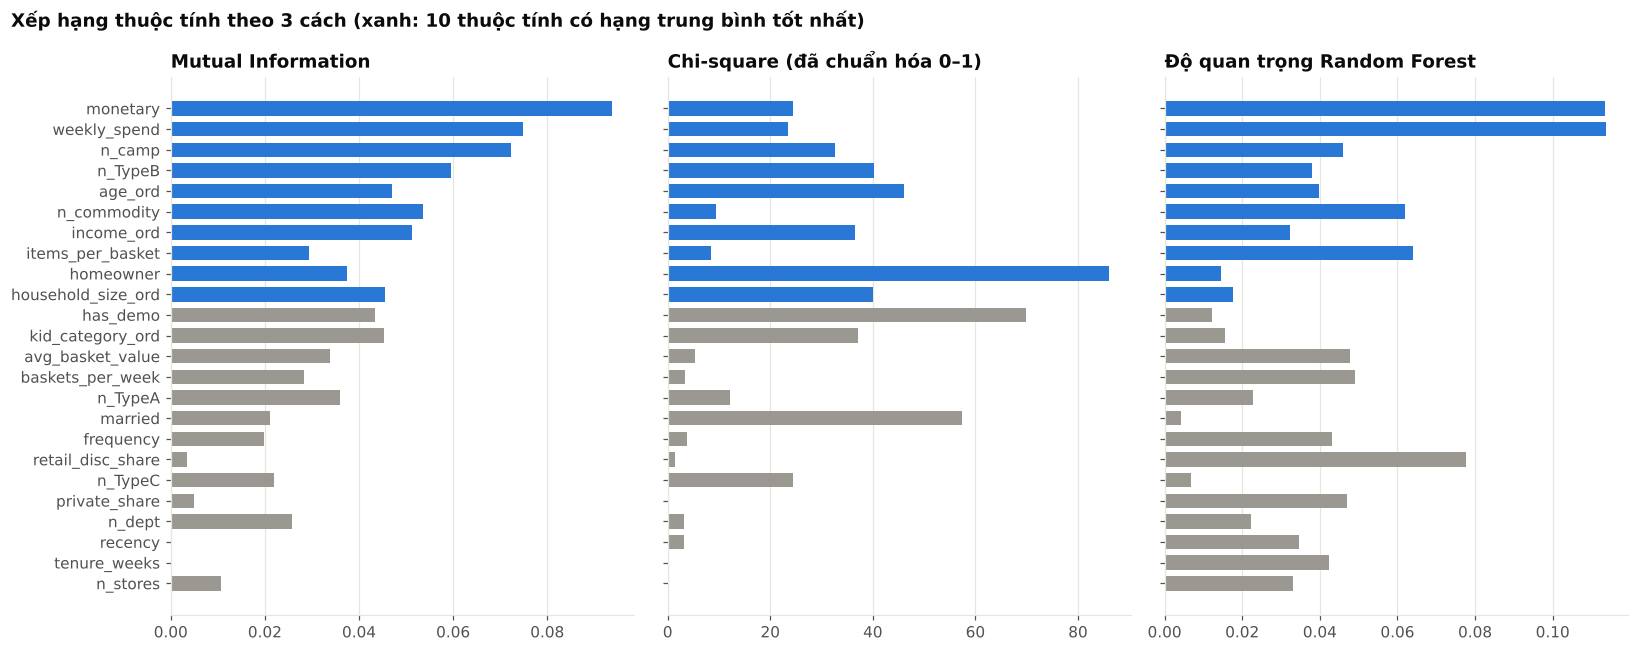

In [9]:
fig, ax = plt.subplots(1,3, figsize=(15,6), sharey=True)
order = rank.index[::-1]
for a,(c,t) in zip(ax,[('MI','Mutual Information'),('Chi2','Chi-square (đã chuẩn hóa 0–1)'),('RF_importance','Độ quan trọng Random Forest')]):
    v = rank.loc[order,c]; a.barh(order, v, color=[BLUE if r<=10 else GRAY for r in rank.loc[order,'hạng_TB'].rank()], height=0.7)
    a.set(title=t); a.grid(axis='y', visible=False)
fig.suptitle('Xếp hạng thuộc tính theo 3 cách (xanh: 10 thuộc tính có hạng trung bình tốt nhất)', x=0.01, ha='left', fontsize=12, fontweight='bold', color=INK)
plt.tight_layout(); save(fig, 'H9_xep_hang_thuoc_tinh')

## 5. Lọc thuộc tính

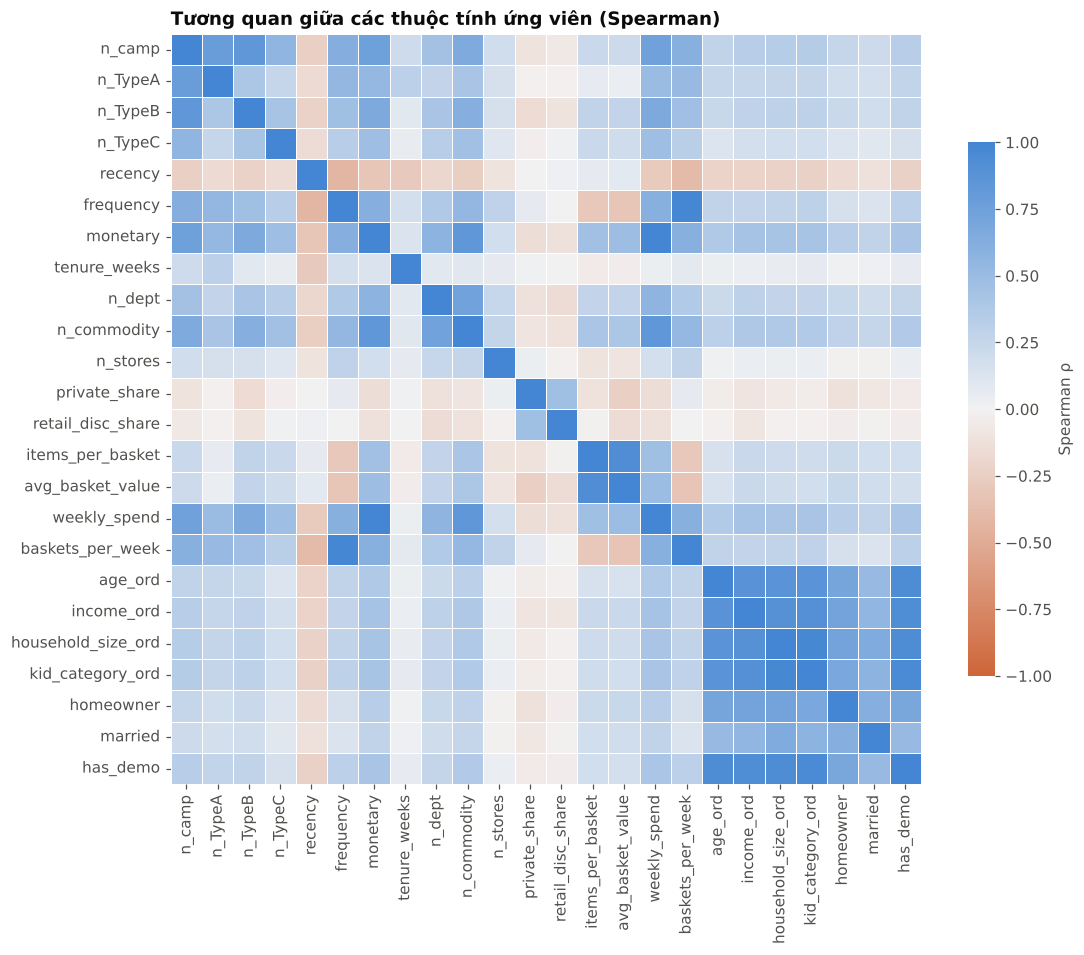

,level_0,level_1,rho
159,monetary,weekly_spend,0.992667
136,frequency,baskets_per_week,0.991982
476,household_size_ord,kid_category_ord,0.980765
503,kid_category_ord,has_demo,0.955793
479,household_size_ord,has_demo,0.939657
431,age_ord,has_demo,0.937540
455,income_ord,has_demo,0.935254
326,items_per_basket,avg_basket_value,0.927116
452,income_ord,kid_category_ord,0.900345


In [10]:
corr = X.corr(method='spearman')
fig, ax = plt.subplots(figsize=(11,9))
sns.heatmap(corr, cmap=sns.diverging_palette(25, 250, s=80, l=55, as_cmap=True), center=0, vmin=-1, vmax=1, ax=ax, square=True,
            linewidths=0.4, linecolor='white', cbar_kws={'shrink':0.7, 'label':'Spearman ρ'})
ax.set_title('Tương quan giữa các thuộc tính ứng viên (Spearman)'); save(fig, 'H10_tuong_quan_thuoc_tinh')
pairs = (corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().rename('rho').reset_index())
high = pairs[pairs.rho.abs()>0.9].sort_values('rho', ascending=False); high

In [11]:
# Quy tắc lọc:
# (1) với mỗi cặp |rho| > 0,9 giữ thuộc tính có hạng trung bình tốt hơn (bỏ thông tin trùng lặp);
# (2) loại thuộc tính "yếu ở cả 3 cách": MI < 0,015 VÀ Chi-square không có ý nghĩa (p > 0,05) VÀ không nằm trong top 10 của Random Forest.
drop_corr = set()
for _,r in high.iterrows():
    a,b = r.level_0, r.level_1
    if a in drop_corr or b in drop_corr: continue
    drop_corr.add(a if rank.loc[a,'hạng_TB'] > rank.loc[b,'hạng_TB'] else b)
weak = rank[(rank.MI<0.015)&(rank.Chi2_p>0.05)]
drop_low = set(weak[weak['hạng_RF_importance']>10].index) - drop_corr
print('Yếu theo MI và Chi2:', list(weak.index), '-> loại:', sorted(drop_low), '| giữ vì RF xếp cao:', sorted(set(weak.index)-drop_low))
decision = pd.DataFrame({'Hạng TB': rank['hạng_TB'].round(1)})
decision['Quyết định'] = 'Giữ'; decision['Lý do'] = ''
for c in drop_corr:
    partner = [x for _,r in high.iterrows() for x in (r.level_0, r.level_1) if c in (r.level_0, r.level_1) and x!=c][0]
    decision.loc[c,['Quyết định','Lý do']] = ['Loại', f'tương quan |ρ|>0,9 với {partner}, hạng kém hơn']
for c in drop_low: decision.loc[c,['Quyết định','Lý do']] = ['Loại', 'MI < 0,015, Chi2 p > 0,05 và ngoài top 10 RF']
for c in set(weak.index)-drop_low: decision.loc[c,'Lý do'] = 'yếu theo MI/Chi2 nhưng RF xếp top 10 -> giữ'
decision.to_csv('../outputs/thuoc_tinh_giu_loai.csv'); decision

Yếu theo MI và Chi2: ['retail_disc_share', 'private_share', 'recency', 'tenure_weeks', 'n_stores'] -> loại: ['n_stores', 'recency', 'tenure_weeks'] | giữ vì RF xếp cao: ['private_share', 'retail_disc_share']


,Hạng TB,Quyết định,Lý do
monetary,4.7,Giữ,
weekly_spend,5.0,Loại,"tương quan |ρ|>0,9 với monetary, hạng kém hơn"
n_camp,7.0,Giữ,
n_TypeB,7.3,Giữ,
age_ord,7.7,Giữ,
n_commodity,8.0,Giữ,
income_ord,10.0,Giữ,
items_per_basket,11.0,Giữ,
homeowner,11.0,Giữ,
household_size_ord,11.0,Giữ,


In [12]:
final_cols = [c for c in X.columns if c not in drop_corr|drop_low]
B1 = hb[final_cols+['redeemed']]
B1.to_csv('../outputs/household_base.csv')
log.append({'Bước':'3. Bộ dữ liệu 1 (cấp hộ)','Số dòng':len(B1),'Số giỏ':None,'Số hộ':len(B1),
            'Ghi chú':f'{len(X.columns)} thuộc tính ứng viên -> giữ {len(final_cols)}; lớp dương {B1.redeemed.mean():.1%}'})
print('Thuộc tính giữ lại:', final_cols)
# Kiểm tra nhanh: lọc thuộc tính không làm giảm khả năng dự đoán (5-fold CV lặp 3 lần, ROC-AUC)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))
for name, cols in [('Trước lọc', list(X.columns)), ('Sau lọc', final_cols)]:
    print(name, len(cols), 'thuộc tính – ROC-AUC LR =', round(cross_val_score(lr, hb[cols], y, cv=cv, scoring='roc_auc').mean(), 4))
bf = pd.DataFrame(log); bf.to_csv('../outputs/bang_truoc_sau.csv', index=False); bf

Thuộc tính giữ lại: ['n_camp', 'n_TypeA', 'n_TypeB', 'n_TypeC', 'monetary', 'n_dept', 'n_commodity', 'private_share', 'retail_disc_share', 'items_per_basket', 'baskets_per_week', 'age_ord', 'income_ord', 'household_size_ord', 'homeowner', 'married']


Trước lọc 24 thuộc tính – ROC-AUC LR = 0.7931
Sau lọc 16 thuộc tính – ROC-AUC LR = 0.7949


,Bước,Số dòng,Số giỏ,Số hộ,Ghi chú
0,0. Dữ liệu gốc (transaction_data),2595732,276484.0,2500,
1,1a. Bỏ SALES_VALUE ≤ 0 hoặc QUANTITY = 0,2576815,275539.0,2500,loại 18.917 dòng
2,1d. Bỏ department/commodity không phải hàng hóa,2543426,250942.0,2500,loại 33.389 dòng
3,2. Bảng giỏ hàng (bỏ trùng sub-commodity trong...,2157526,250942.0,2500,
4,3. Bộ dữ liệu 1 (cấp hộ),1584,NaN,1584,24 thuộc tính ứng viên -> giữ 16; lớp dương 27.4%


## 7. Chia train/test dùng chung cho Bước 3 và Bước 4 (hướng B)
Chia **một lần duy nhất** 1.584 hộ theo `household_key` (80/20, phân tầng theo nhãn, `random_state=42`). Bước 3 chỉ được dùng giỏ hàng và nhãn của hộ **không thuộc tập test** để tìm và chọn luật; Bước 4 dùng đúng cách chia này. Nhờ vậy tập test không ảnh hưởng đến luật và đặc trưng (tránh rò rỉ dữ liệu).

In [13]:
from sklearn.model_selection import train_test_split
hb_s = pd.read_csv('../outputs/household_base.csv')
tr_hh, te_hh = train_test_split(hb_s.household_key, test_size=0.2, stratify=hb_s.redeemed, random_state=42)
split = pd.DataFrame({'household_key': hb_s.household_key})
split['set'] = np.where(split.household_key.isin(te_hh), 'test', 'train')
split.to_csv('../outputs/split.csv', index=False)
print(split.set.value_counts())
print('Tỷ lệ lớp dương  train: {:.1%}  test: {:.1%}'.format(*[hb_s.redeemed[split.set==s].mean() for s in ['train','test']]))

set
train    1267
test      317
Name: count, dtype: int64
Tỷ lệ lớp dương  train: 27.4%  test: 27.4%
